#### Multimodal AI project source code:

In [1]:
!pip install transformers datasets torchaudio evaluate librosa

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.2 MB/s eta 0:00:00


In [2]:
!pip install -q -U google-generativeai tqdm scikit-learn seaborn matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 31.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 43.6 MB/s eta 0:00:00


##### Dataset upload, initialization and preprocessing:

In [ ]:
import os
import random
import shutil
import pandas as pd

# Custom Ukrainian dataset emotion mapping based on the provided list
ukr_emotion_map = {
    1: "happy",      # радість
    2: "sad",        # сум
    3: "angry",      # злість
    4: "fearful",    # страх
    5: "surprised",  # здивування
    6: "disgust",    # огида
    7: "calm",       # спокій
    8: "neutral"     # нейтральність
}

def extract_labels_ukr(filename):
    """
    Extracts metadata from the filename based on the format:
    [Emotion]-[Statement]-[Actor].ogg
    """
    # Remove the .ogg extension and split by hyphen
    parts = os.path.splitext(filename)[0].split('-')

    emotion_idx = int(parts[0])
    statement_idx = int(parts[1])
    actor_idx = int(parts[2])

    # Determine gender: odd IDs = Female, even IDs = Male
    gender = "Female" if actor_idx % 2 != 0 else "Male"

    # Determine the statement
    statement = "Діти розмовляють біля дверей" if statement_idx == 1 else "Їжа вже на столі"

    return {
        'emotion': ukr_emotion_map.get(emotion_idx, "unknown"),
        'statement': statement,
        'actor': actor_idx,
        'gender': gender
    }

def create_ukr_df(data_dir):
    """
    Creates a Pandas DataFrame containing file paths and metadata for all audio files.
    """
    audio_files = []
    metadata = []

    # Iterate through all actor folders
    for root, _, files in os.walk(data_dir):
        for file in files:
            if file.endswith(".ogg"): # Ensure we only process .ogg files
                audio_files.append(os.path.join(root, file))
                metadata.append(extract_labels_ukr(file))

    df = pd.DataFrame(metadata)

    # Convert data types for consistency
    for col in ['emotion', 'statement', 'gender']:
        df[col] = df[col].astype(str)
    df['actor'] = df['actor'].astype(int)

    # Map text emotions back to numeric labels (useful for training/evaluation)
    emotion_to_label = {v: (k - 1) for k, v in ukr_emotion_map.items()}
    df['emotion_label'] = df['emotion'].map(emotion_to_label)

    # Insert the file path as the first column
    df.insert(0, 'file_path', audio_files)
    return df

In [ ]:
import zipfile
import os

zip_file_path = 'ukr-emotions-dataset.zip'
ukr_data_dir = './ukr_dataset'
os.makedirs(ukr_data_dir, exist_ok=True)
print(f"Unpacking {zip_file_path}...")

try:
    with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
        zip_ref.extractall(ukr_data_dir)
    print(f"Successfully unpacked to: {ukr_data_dir}")
    extracted_folders = os.listdir(ukr_data_dir)
    print(f"Found {len(extracted_folders)} items/folders inside.")

except FileNotFoundError:
    print(f"Error: The file '{zip_file_path}' was not found. Please check the name.")
except zipfile.BadZipFile:
    print("Error: The uploaded file is not a valid zip archive.")

Unpacking ukr-emotions-dataset.zip...
Successfully unpacked to: ./ukr_dataset
Found 15 items/folders inside.


Data splitting logic:

In [ ]:
import os
import random
import re

ukr_data_dir = './ukr_dataset'
ukr_train_dir = './ukr_train_dataset'
ukr_val_dir = './ukr_val_dataset'
ukr_test_dir = './ukr_test_dataset'

os.makedirs(ukr_train_dir, exist_ok=True)
os.makedirs(ukr_val_dir, exist_ok=True)
os.makedirs(ukr_test_dir, exist_ok=True)

ukr_content_list = [folder for folder in os.listdir(ukr_data_dir) if os.path.isdir(os.path.join(ukr_data_dir, folder))]

test_samples_per_gender = 1
val_samples_per_gender = 1

test_male = test_female = 0
val_male = val_female = 0

train_actors, val_actors, test_actors = [], [], []
random.shuffle(ukr_content_list)

# Distribute actors into train, validation, and test sets
for item in ukr_content_list:
    numbers = re.findall(r'\d+', item)
    if not numbers:
        continue

    actor_id = int(numbers[0])
    if actor_id % 2 != 0:  # Female actors (Odd IDs)
        if test_female < test_samples_per_gender:
            test_actors.append(item)
            test_female += 1
        elif val_female < val_samples_per_gender:
            val_actors.append(item)
            val_female += 1
        else:
            train_actors.append(item)

    else:  # Male actors (Even IDs)
        if test_male < test_samples_per_gender:
            test_actors.append(item)
            test_male += 1
        elif val_male < val_samples_per_gender:
            val_actors.append(item)
            val_male += 1
        else:
            train_actors.append(item)

print(f"Train actors: {train_actors}")
print(f"Validation actors: {val_actors}")
print(f"Test actors: {test_actors}")

Train actors: ['actor 4', 'actor 8', 'actor 15', 'actor 1', 'actor 7', 'actor 5', 'actor 13', 'actor 9', 'actor 6', 'actor 12', 'actor 3']
Validation actors: ['actor 10', 'actor 17']
Test actors: ['actor 2', 'actor 11']


Copying Files and Finalizing DataFrames:

In [ ]:
def copy_directory(src, dst):
    """
    Safely copies a directory. If the destination exists, it overwrites it.
    """
    if os.path.exists(dst):
        shutil.rmtree(dst)
    shutil.copytree(src, dst)

for actor_folder in ukr_content_list:
    source_path = os.path.join(ukr_data_dir, actor_folder)

    if actor_folder in test_actors:
        destination_path = os.path.join(ukr_test_dir, actor_folder)
    elif actor_folder in val_actors:
        destination_path = os.path.join(ukr_val_dir, actor_folder)
    elif actor_folder in train_actors:
        destination_path = os.path.join(ukr_train_dir, actor_folder)
    else:
        continue
    copy_directory(source_path, destination_path)

ukr_train_df = create_ukr_df(ukr_train_dir)
ukr_val_df = create_ukr_df(ukr_val_dir)
ukr_test_df = create_ukr_df(ukr_test_dir)

print("Train dataset preview:")
display(ukr_train_df.head())

Train dataset preview:


,file_path,emotion,statement,actor,gender,emotion_label
0,./ukr_train_dataset/actor 15/06-01-15.ogg,disgust,Діти розмовляють біля дверей,15,Female,5
1,./ukr_train_dataset/actor 15/03-02-15.ogg,angry,Їжа вже на столі,15,Female,2
2,./ukr_train_dataset/actor 15/05-02-15.ogg,surprised,Їжа вже на столі,15,Female,4
3,./ukr_train_dataset/actor 15/08-01-15.ogg,neutral,Діти розмовляють біля дверей,15,Female,7
4,./ukr_train_dataset/actor 15/06-02-15.ogg,disgust,Їжа вже на столі,15,Female,5


##### New model fine-tunning:

In [3]:
import os
import re
import shutil
import zipfile
import librosa
import soundfile as sf
import pandas as pd

# 1. Unpacking Dataset
zip_file_path = 'ukr-emotions-dataset.zip'
ukr_data_dir = './ukr_dataset'
os.makedirs(ukr_data_dir, exist_ok=True)
print(f"Unpacking {zip_file_path}...")

try:
    with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
        zip_ref.extractall(ukr_data_dir)
    print(f"Successfully unpacked to: {ukr_data_dir}")
except FileNotFoundError:
    print(f"Error: The file '{zip_file_path}' was not found.")
except zipfile.BadZipFile:
    print("Error: The uploaded file is not a valid zip archive.")

# 2. Setup Split Directories
ukr_train_dir = './ukr_train_dataset'
ukr_val_dir = './ukr_val_dataset'
ukr_test_dir = './ukr_test_dataset'

os.makedirs(ukr_train_dir, exist_ok=True)
os.makedirs(ukr_val_dir, exist_ok=True)
os.makedirs(ukr_test_dir, exist_ok=True)

ukr_content_list = [folder for folder in os.listdir(ukr_data_dir) if os.path.isdir(os.path.join(ukr_data_dir, folder))]

test_samples_per_gender = 1
val_samples_per_gender = 1
test_male = test_female = 0
val_male = val_female = 0
train_actors, val_actors, test_actors = [], [], []

import random
random.shuffle(ukr_content_list)

# Distribute actors into train, validation, and test sets
for item in ukr_content_list:
    numbers = re.findall(r'\d+', item)
    if not numbers:
        continue

    actor_id = int(numbers[0])
    if actor_id % 2 != 0:  # Female actors
        if test_female < test_samples_per_gender:
            test_actors.append(item)
            test_female += 1
        elif val_female < val_samples_per_gender:
            val_actors.append(item)
            val_female += 1
        else:
            train_actors.append(item)
    else:  # Male actors
        if test_male < test_samples_per_gender:
            test_actors.append(item)
            test_male += 1
        elif val_male < val_samples_per_gender:
            val_actors.append(item)
            val_male += 1
        else:
            train_actors.append(item)

def copy_directory(src, dst):
    if os.path.exists(dst):
        shutil.rmtree(dst)
    shutil.copytree(src, dst)

# Copy folders to split destinations
for actor_folder in ukr_content_list:
    source_path = os.path.join(ukr_data_dir, actor_folder)
    if actor_folder in test_actors:
        destination_path = os.path.join(ukr_test_dir, actor_folder)
    elif actor_folder in val_actors:
        destination_path = os.path.join(ukr_val_dir, actor_folder)
    elif actor_folder in train_actors:
        destination_path = os.path.join(ukr_train_dir, actor_folder)
    else:
        continue
    copy_directory(source_path, destination_path)

# 3. Standardize and Convert All Audio to .wav format
def standardize_audio_files(base_dir, target_sr=22050):
    """
    Scans directory, loads any .ogg/.m4a/.wav file, converts them to
    monophonic .wav at target_sr, and removes the old non-wav files.
    """
    for root, _, files in os.walk(base_dir):
        for file in files:
            if file.lower().endswith((".ogg", ".m4a", ".wav")):
                file_path = os.path.join(root, file)

                # Load with librosa (automatically handles decoding m4a/ogg/wav, converts to mono, and resamples)
                try:
                    y, sr = librosa.load(file_path, sr=target_sr, mono=True)

                    # Define new .wav filename path
                    base_name = os.path.splitext(file)[0]
                    wav_filename = f"{base_name}.wav"
                    wav_path = os.path.join(root, wav_filename)

                    # Save out as standard PCM .wav
                    sf.write(wav_path, y, target_sr)

                    # If the original file wasn't a wav, remove it to clean up
                    if not file.lower().endswith(".wav"):
                        os.remove(file_path)
                except Exception as e:
                    print(f"Error processing {file_path}: {e}")

print("Standardizing dataset audio formats to .wav...")
standardize_audio_files(ukr_train_dir)
standardize_audio_files(ukr_val_dir)
standardize_audio_files(ukr_test_dir)
print("Standardization complete!")

# 4. Emotion Mapping & DataFrame Creation
ukr_emotion_map = {
    1: "happy", 2: "sad", 3: "angry", 4: "fearful",
    5: "surprised", 6: "disgust", 7: "calm", 8: "neutral"
}

def extract_labels_ukr(filename):
    parts = os.path.splitext(filename)[0].split('-')
    emotion_idx = int(parts[0])
    statement_idx = int(parts[1])
    actor_idx = int(parts[2])
    gender = "Female" if actor_idx % 2 != 0 else "Male"
    statement = "Діти розмовляють біля дверей" if statement_idx == 1 else "Їжа вже на столі"

    return {
        'emotion': ukr_emotion_map.get(emotion_idx, "unknown"),
        'statement': statement,
        'actor': actor_idx,
        'gender': gender
    }

def create_ukr_df(data_dir):
    audio_files = []
    metadata = []

    for root, _, files in os.walk(data_dir):
        for file in files:
            if file.lower().endswith(".wav"):
                audio_files.append(os.path.join(root, file))
                metadata.append(extract_labels_ukr(file))

    df = pd.DataFrame(metadata)
    for col in ['emotion', 'statement', 'gender']:
        df[col] = df[col].astype(str)
    df['actor'] = df['actor'].astype(int)

    emotion_to_label = {v: (k - 1) for k, v in ukr_emotion_map.items()}
    df['emotion_label'] = df['emotion'].map(emotion_to_label)
    df.insert(0, 'file_path', audio_files)
    return df

ukr_train_df = create_ukr_df(ukr_train_dir)
ukr_val_df = create_ukr_df(ukr_val_dir)
ukr_test_df = create_ukr_df(ukr_test_dir)

print("Train dataset preview:")
display(ukr_train_df.head())

Unpacking ukr-emotions-dataset.zip...
Successfully unpacked to: ./ukr_dataset
Standardizing dataset audio formats to .wav...


/tmp/ipykernel_1586/4270564220.py:101: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(file_path, sr=target_sr, mono=True)
/usr/local/lib/python3.12/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)
/tmp/ipykernel_1586/4270564220.py:101: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(file_path, sr=target_sr, mono=True)
/usr/local/lib/python3.12/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)
/tmp/ipykernel_1586/4270564220.py:101: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(file_path, sr=target_sr, mo

Standardization complete!
Train dataset preview:


,file_path,emotion,statement,actor,gender,emotion_label
0,./ukr_train_dataset/actor 20/08-01-20.wav,neutral,Діти розмовляють біля дверей,20,Male,7
1,./ukr_train_dataset/actor 20/05-01-20.wav,surprised,Діти розмовляють біля дверей,20,Male,4
2,./ukr_train_dataset/actor 20/08-02-20.wav,neutral,Їжа вже на столі,20,Male,7
3,./ukr_train_dataset/actor 20/04-01-20.wav,fearful,Діти розмовляють біля дверей,20,Male,3
4,./ukr_train_dataset/actor 20/03-01-20.wav,angry,Діти розмовляють біля дверей,20,Male,2


In [4]:
import torch
import torchaudio
import numpy as np
import evaluate
from datasets import Dataset
from transformers import (
    AutoFeatureExtractor,
    HubertForSequenceClassification,
    TrainingArguments,
    Trainer
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [5]:
model_checkpoint = "superb/hubert-large-superb-er"
feature_extractor = AutoFeatureExtractor.from_pretrained(model_checkpoint)

def load_and_resample_audio(batch):
    """
    Loads audio file and resamples it to 16kHz for HuBERT.
    """
    speech_array, sampling_rate = torchaudio.load(batch["file_path"])

    # Resample if the sample rate is not 16000
    if sampling_rate != feature_extractor.sampling_rate:
        resampler = torchaudio.transforms.Resample(sampling_rate, feature_extractor.sampling_rate)
        speech_array = resampler(speech_array)

    # Squeeze to 1D array
    batch["speech"] = speech_array.squeeze().numpy()
    return batch

def prepare_dataset(batch):
    """
    Extracts features from the audio array to feed into the model.
    """
    audio = batch["speech"]
    inputs = feature_extractor(audio, sampling_rate=feature_extractor.sampling_rate, max_length=16000*5, truncation=True)
    batch["input_values"] = inputs.input_values[0]

    # Hugging Face expects the label column to be named 'labels'
    batch["labels"] = batch["emotion_label"]
    return batch

train_dataset = Dataset.from_pandas(ukr_train_df)
val_dataset = Dataset.from_pandas(ukr_val_df)
test_dataset = Dataset.from_pandas(ukr_test_df)

print("Processing Train dataset...")
train_dataset = train_dataset.map(load_and_resample_audio).map(prepare_dataset, remove_columns=train_dataset.column_names)

print("Processing Validation dataset...")
val_dataset = val_dataset.map(load_and_resample_audio).map(prepare_dataset, remove_columns=val_dataset.column_names)

print("Processing Test dataset...")
test_dataset = test_dataset.map(load_and_resample_audio).map(prepare_dataset, remove_columns=test_dataset.column_names)

preprocessor_config.json:   0%|          | 0.00/212 [00:00<?, ?B/s]

Processing Train dataset...


Map:   0%|          | 0/347 [00:00<?, ? examples/s]

Map:   0%|          | 0/347 [00:00<?, ? examples/s]

Processing Validation dataset...


Map:   0%|          | 0/32 [00:00<?, ? examples/s]

Map:   0%|          | 0/32 [00:00<?, ? examples/s]

Processing Test dataset...


Map:   0%|          | 0/32 [00:00<?, ? examples/s]

Map:   0%|          | 0/32 [00:00<?, ? examples/s]

In [6]:
num_labels = 8
id2label = {(k - 1): v for k, v in ukr_emotion_map.items()}
label2id = {v: (k - 1) for k, v in ukr_emotion_map.items()}

# ==========================================
# MODEL 1: Original Base HuBERT
# ==========================================
print("Loading Model 1 (Base HuBERT)...")
model_1_base = HubertForSequenceClassification.from_pretrained(
    model_checkpoint,
    num_labels=num_labels,
    label2id=label2id,
    id2label=id2label,
    ignore_mismatched_sizes=True # Required if the base model had a different number of labels
)
model_1_base.to(device)


# ==========================================
# MODEL 2: Bachelor's Fine-Tuned Model
# ==========================================
print("Loading Model 2 (Bachelor Fine-Tuned)...")
model_2_bachelor = HubertForSequenceClassification.from_pretrained(
    model_checkpoint,
    num_labels=num_labels,
    label2id=label2id,
    id2label=id2label,
    ignore_mismatched_sizes=True
)

bachelor_weights_path = "ravdess-tess-hubert-model-best.pth"
try:
    model_2_bachelor.load_state_dict(torch.load(bachelor_weights_path, map_location=device))
    print("Successfully loaded bachelor model weights!")
except Exception as e:
    print(f"Warning: Could not load weights directly. Error: {e}")
model_2_bachelor.to(device)

Loading Model 1 (Base HuBERT)...


config.json:   0%|          | 0.00/1.83k [00:00<?, ?B/s]

[transformers] You passed `num_labels=8` which is incompatible to the `id2label` map of length `4`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.26GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

... (4 outputs left out)

Loading Model 2 (Bachelor Fine-Tuned)...


Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

[transformers] HubertForSequenceClassification LOAD REPORT from: superb/hubert-large-superb-er
Key               | Status   |                                                                                       
------------------+----------+---------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([4, 256]) vs model:torch.Size([8, 256])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([4]) vs model:torch.Size([8])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


HubertForSequenceClassification(
  (hubert): HubertModel(
    (feature_extractor): HubertFeatureEncoder(
      (conv_layers): ModuleList(
        (0): HubertLayerNormConvLayer(
          (conv): Conv1d(1, 512, kernel_size=(10,), stride=(5,))
          (layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (activation): GELUActivation()
        )
        (1-4): 4 x HubertLayerNormConvLayer(
          (conv): Conv1d(512, 512, kernel_size=(3,), stride=(2,))
          (layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (activation): GELUActivation()
        )
        (5-6): 2 x HubertLayerNormConvLayer(
          (conv): Conv1d(512, 512, kernel_size=(2,), stride=(2,))
          (layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (activation): GELUActivation()
        )
      )
    )
    (feature_projection): HubertFeatureProjection(
      (layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
      (pro

In [9]:
accuracy_metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    if isinstance(predictions, tuple):
        predictions = predictions[0]
    predictions = np.argmax(predictions, axis=1)

    return accuracy_metric.compute(predictions=predictions, references=labels)

def train_model(model, output_directory_name):
    """
    Sets up the Trainer and fine-tunes the provided model.
    """
    training_args = TrainingArguments(
        output_dir=f"./{output_directory_name}",
        eval_strategy="epoch",
        save_strategy="epoch",
        learning_rate=3e-5,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        gradient_accumulation_steps=2,
        num_train_epochs=10, # ToDo: increase number of epochs
        warmup_steps=20,
        logging_steps=10,
        load_best_model_at_end=True,
        metric_for_best_model="accuracy",
        save_total_limit=2,
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        processing_class=feature_extractor,
        compute_metrics=compute_metrics,
    )

    print(f"--- Starting training for {output_directory_name} ---")
    trainer.train()

    print(f"--- Final Evaluation on TEST set for {output_directory_name} ---")
    test_results = trainer.evaluate(test_dataset)
    print(test_results)

    return trainer

In [10]:
import json
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

def evaluate_and_save(trainer, test_dataset, model_name, output_filename):
    print(f"--- Evaluating and saving metrics for {model_name} ---")
    predictions_output = trainer.predict(test_dataset)

    logits = predictions_output.predictions
    if isinstance(logits, tuple):
        logits = logits[0]

    y_pred = np.argmax(logits, axis=1)
    y_true = predictions_output.label_ids

    accuracy = accuracy_score(y_true, y_pred)
    report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    cm = confusion_matrix(y_true, y_pred).tolist()

    results = {
        "model_name": model_name,
        "accuracy": accuracy,
        "classification_report": report,
        "confusion_matrix": cm
    }

    with open(output_filename, 'w', encoding='utf-8') as f:
        json.dump(results, f, indent=4)

    print(f"All metrics saved successfully to {output_filename}")

In [11]:
import torch
import gc

trainer_1 = train_model(model_1_base, "hubert_base_ukr_finetuned")
evaluate_and_save(trainer_1, test_dataset, "Base HuBERT", "metrics_base.json")

# print("Cleaning up GPU memory after Model 1...")
# del trainer_1
# del model_1_base
# gc.collect()
# torch.cuda.empty_cache()

# print(f"Memory allocated: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

--- Starting training for hubert_base_ukr_finetuned ---


Epoch,Training Loss,Validation Loss,Accuracy
1,4.251655,2.124717,0.187500
2,4.156187,2.049346,0.156250
3,4.051909,2.042994,0.125000
4,3.957971,1.993480,0.187500
5,3.842860,1.964207,0.218750
6,3.782148,1.928999,0.218750
7,3.696363,1.923183,0.250000
8,3.617883,1.916494,0.281250
9,3.589604,1.914605,0.250000
10,3.614959,1.898535,0.187500


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (7 outputs left out)

--- Final Evaluation on TEST set for hubert_base_ukr_finetuned ---


Training Loss,Validation Loss,Epoch,Accuracy
3.614959,1.720450,10,0.375000


{'eval_loss': 1.7204501628875732, 'eval_accuracy': 0.375}
--- Evaluating and saving metrics for Base HuBERT ---


All metrics saved successfully to metrics_base.json


In [12]:
print("Cleaning up GPU memory after Model 1...")
del trainer_1
del model_1_base
gc.collect()
torch.cuda.empty_cache()

print(f"Memory allocated: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

Cleaning up GPU memory after Model 1...
Memory allocated: 1.28 GB


In [13]:
trainer_2 = train_model(model_2_bachelor, "hubert_bachelor_ukr_finetuned")
evaluate_and_save(trainer_2, test_dataset, "Bachelor Fine-Tuned", "metrics_bachelor.json")

--- Starting training for hubert_bachelor_ukr_finetuned ---


Epoch,Training Loss,Validation Loss,Accuracy
1,4.360141,2.152054,0.125000
2,4.234097,2.082862,0.156250
3,4.080141,2.026010,0.156250
4,4.005542,2.007438,0.218750
5,3.961000,1.969814,0.187500
6,3.800055,1.942919,0.281250
7,3.806887,1.920470,0.281250
8,3.641967,1.908394,0.250000
9,3.620541,1.898339,0.281250
10,3.612302,1.897607,0.281250


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (6 outputs left out)

--- Final Evaluation on TEST set for hubert_bachelor_ukr_finetuned ---


Training Loss,Validation Loss,Epoch,Accuracy
3.612302,1.824635,10,0.281250


{'eval_loss': 1.8246345520019531, 'eval_accuracy': 0.28125}
--- Evaluating and saving metrics for Bachelor Fine-Tuned ---


All metrics saved successfully to metrics_bachelor.json


In [ ]:
# print("Cleaning up GPU memory after Model 2...")
# del trainer_2
# del model_2_bachelor
# gc.collect()
# torch.cuda.empty_cache()

# print(f"Memory allocated: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

Cleaning up GPU memory after Model 2...
Memory allocated: 1.28 GB


##### Zero-shot model testing:

In [ ]:
print("Loading Model 2 (Bachelor Fine-Tuned)...")
model_2_bachelor = HubertForSequenceClassification.from_pretrained(
    model_checkpoint,
    num_labels=num_labels,
    label2id=label2id,
    id2label=id2label,
    ignore_mismatched_sizes=True
)

bachelor_weights_path = "ravdess-tess-hubert-model-best.pth"
try:
    model_2_bachelor.load_state_dict(torch.load(bachelor_weights_path, map_location=device))
    print("Successfully loaded bachelor model weights!")
except Exception as e:
    print(f"Warning: Could not load weights directly. Error: {e}")
model_2_bachelor.to(device)

Loading Model 2 (Bachelor Fine-Tuned)...


Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

HubertForSequenceClassification LOAD REPORT from: superb/hubert-large-superb-er
Key               | Status   |                                                                                     
------------------+----------+-------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([4, 256]) vs model:torch.Size([8, 256])
classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([4]) vs model:torch.Size([8])          

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


	size mismatch for classifier.weight: copying a param with shape torch.Size([7, 256]) from checkpoint, the shape in current model is torch.Size([8, 256]).
	size mismatch for classifier.bias: copying a param with shape torch.Size([7]) from checkpoint, the shape in current model is torch.Size([8]).


HubertForSequenceClassification(
  (hubert): HubertModel(
    (feature_extractor): HubertFeatureEncoder(
      (conv_layers): ModuleList(
        (0): HubertLayerNormConvLayer(
          (conv): Conv1d(1, 512, kernel_size=(10,), stride=(5,))
          (layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (activation): GELUActivation()
        )
        (1-4): 4 x HubertLayerNormConvLayer(
          (conv): Conv1d(512, 512, kernel_size=(3,), stride=(2,))
          (layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (activation): GELUActivation()
        )
        (5-6): 2 x HubertLayerNormConvLayer(
          (conv): Conv1d(512, 512, kernel_size=(2,), stride=(2,))
          (layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (activation): GELUActivation()
        )
      )
    )
    (feature_projection): HubertFeatureProjection(
      (layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
      (pro

--- Running Zero-Shot Evaluation on Ukrainian Test Set ---



Zero-Shot Baseline Accuracy: 12.50%

Zero-Shot Classification Report:

              precision    recall  f1-score   support

       happy       0.00      0.00      0.00         4
         sad       0.00      0.00      0.00         4
       angry       0.00      0.00      0.00         4
     fearful       0.00      0.00      0.00         4
   surprised       0.11      0.75      0.19         4
     disgust       0.00      0.00      0.00         4
        calm       0.00      0.00      0.00         4
     neutral       0.33      0.25      0.29         4

    accuracy                           0.12        32
   macro avg       0.06      0.12      0.06        32
weighted avg       0.06      0.12      0.06        32



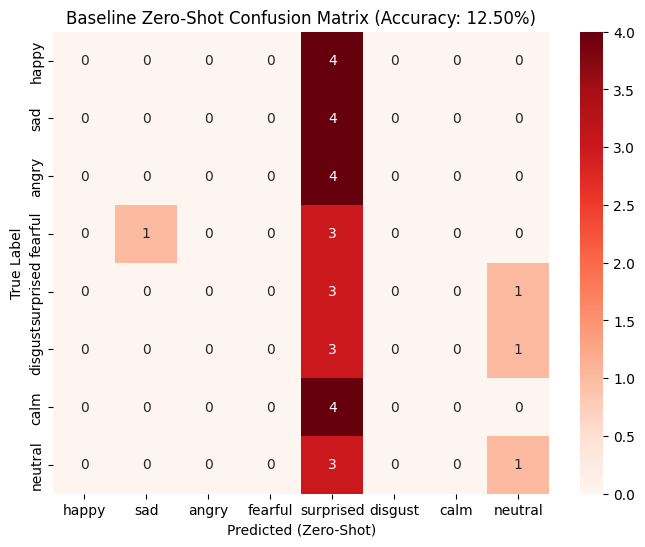

Zero-Shot metrics saved to metrics_zero_shot.json


In [ ]:
import numpy as np
import json
from transformers import Trainer, TrainingArguments
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

zero_shot_args = TrainingArguments(
    output_dir="./zero_shot_results",
    per_device_eval_batch_size=8,
    report_to="none" # Disables external logging since we are just evaluating
)

# Initialize a Trainer using your bachelor model and the fixed compute_metrics function
zero_shot_trainer = Trainer(
    model=model_2_bachelor,
    args=zero_shot_args,
    processing_class=feature_extractor,
    compute_metrics=compute_metrics
)

print("--- Running Zero-Shot Evaluation on Ukrainian Test Set ---")
predictions_output = zero_shot_trainer.predict(test_dataset)

# Extract logits and labels safely
logits = predictions_output.predictions
if isinstance(logits, tuple):
    logits = logits[0]

y_pred_zero_shot = np.argmax(logits, axis=1)
y_true_zero_shot = predictions_output.label_ids

zs_accuracy = accuracy_score(y_true_zero_shot, y_pred_zero_shot)
print(f"\nZero-Shot Baseline Accuracy: {zs_accuracy * 100:.2f}%\n")

labels_names = ["happy", "sad", "angry", "fearful", "surprised", "disgust", "calm", "neutral"]
print("Zero-Shot Classification Report:\n")
report = classification_report(y_true_zero_shot, y_pred_zero_shot, target_names=labels_names, zero_division=0)
print(report)

cm_zs = confusion_matrix(y_true_zero_shot, y_pred_zero_shot)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_zs, annot=True, fmt="d", cmap="Reds", xticklabels=labels_names, yticklabels=labels_names)
plt.xlabel("Predicted (Zero-Shot)")
plt.ylabel("True Label")
plt.title(f"Baseline Zero-Shot Confusion Matrix (Accuracy: {zs_accuracy*100:.2f}%)")
plt.show()

zs_results = {
    "model_name": "Zero-Shot Bachelor Model",
    "accuracy": zs_accuracy,
    "classification_report": classification_report(y_true_zero_shot, y_pred_zero_shot, output_dict=True, zero_division=0),
    "confusion_matrix": cm_zs.tolist()
}

with open("metrics_zero_shot.json", 'w', encoding='utf-8') as f:
    json.dump(zs_results, f, indent=4)

print("Zero-Shot metrics saved to metrics_zero_shot.json")

In [ ]:
del model_2_bachelor
gc.collect()
torch.cuda.empty_cache()

print(f"Memory allocated: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

Memory allocated: 2.55 GB


##### LLMs evaluation:

In [ ]:
import os
import time
import pandas as pd
import google.generativeai as genai
from tqdm.auto import tqdm
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import userdata

GOOGLE_API_KEY = userdata.get('GOOGLE_API_KEY')
genai.configure(api_key=GOOGLE_API_KEY)
model = genai.GenerativeModel('gemini-2.5-flash')
print("API configured successfully!")

system_prompt = """
You are an expert in Speech Emotion Recognition.
Listen to the provided Ukrainian audio file and classify the speaker's emotion.
You MUST choose exactly ONE label from the following list:
happy, sad, angry, fearful, surprised, disgust, calm, neutral.

Do not provide any explanations, punctuation, or extra text. Output ONLY the label word.
"""

def evaluate_llm(test_df):
    predicted_labels = []
    actual_labels = test_df['emotion'].tolist()
    valid_emotions = ["happy", "sad", "angry", "fearful", "surprised", "disgust", "calm", "neutral"]

    print("Starting LLM Evaluation...")
    for index, row in tqdm(test_df.iterrows(), total=len(test_df)):
        audio_path = row['file_path']
        try:
            uploaded_audio = genai.upload_file(path=audio_path)
            response = model.generate_content([system_prompt, uploaded_audio])
            prediction = response.text.strip().lower()

            # Fallback in case the LLM outputs a sentence instead of just the word
            if prediction not in valid_emotions:
                matched = False
                for valid_emotion in valid_emotions:
                    if valid_emotion in prediction:
                        prediction = valid_emotion
                        matched = True
                        break
                if not matched:
                    prediction = "unknown"

            predicted_labels.append(prediction)
            genai.delete_file(uploaded_audio.name)
            time.sleep(2)

        except Exception as e:
            print(f"Error processing {audio_path}: {e}")
            predicted_labels.append("error")

    return actual_labels, predicted_labels

y_true, y_pred_llm = evaluate_llm(ukr_test_df)

API configured successfully!
Starting LLM Evaluation...


  0%|          | 0/32 [00:00<?, ?it/s]

Error processing ./ukr_test_dataset/actor 2/05-02-02.ogg: 429 POST https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-flash:generateContent?%24alt=json%3Benum-encoding%3Dint: You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 5, model: gemini-2.5-flash
Please retry in 38.522908228s.


Error processing ./ukr_test_dataset/actor 2/08-01-02.ogg: 429 POST https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-flash:generateContent?%24alt=json%3Benum-encoding%3Dint: You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 5, model: gemini-2.5-flash
Please retry in 36.068387955s.


Error processing ./ukr_test_dataset/actor 2/01-01-02.ogg: 429 POST https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-flash:generateContent?%24alt=json%3Benum-encoding%3Dint: You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-2.5-flash
Please retry in 3.481290147s.


Error processing ./ukr_test_dataset/actor 2/04-02-02.ogg: 429 POST https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-flash:generateContent?%24alt=json%3Benum-encoding%3Dint: You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-2.5-flash
Please retry in 853.225698ms.


... (3 outputs left out)

Error processing ./ukr_test_dataset/actor 2/07-01-02.ogg: 429 POST https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-flash:generateContent?%24alt=json%3Benum-encoding%3Dint: You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-2.5-flash
Please retry in 50.54426289s.


Error processing ./ukr_test_dataset/actor 2/06-02-02.ogg: 429 POST https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-flash:generateContent?%24alt=json%3Benum-encoding%3Dint: You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-2.5-flash
Please retry in 47.975065616s.


Error processing ./ukr_test_dataset/actor 2/07-02-02.ogg: 429 POST https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-flash:generateContent?%24alt=json%3Benum-encoding%3Dint: You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-2.5-flash
Please retry in 45.343056457s.


Error processing ./ukr_test_dataset/actor 2/02-01-02.ogg: 429 POST https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-flash:generateContent?%24alt=json%3Benum-encoding%3Dint: You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-2.5-flash
Please retry in 42.827490235s.



--- LLM Evaluation Complete ---
Overall LLM Accuracy: 9.38%

Classification Report:

              precision    recall  f1-score   support

       happy       0.00      0.00      0.00         4
         sad       0.00      0.00      0.00         4
       angry       0.00      0.00      0.00         4
     fearful       0.00      0.00      0.00         4
   surprised       0.00      0.00      0.00         4
     disgust       0.00      0.00      0.00         4
        calm       0.00      0.00      0.00         4
     neutral       0.17      0.75      0.27         4

   micro avg       0.14      0.09      0.11        32
   macro avg       0.02      0.09      0.03        32
weighted avg       0.02      0.09      0.03        32



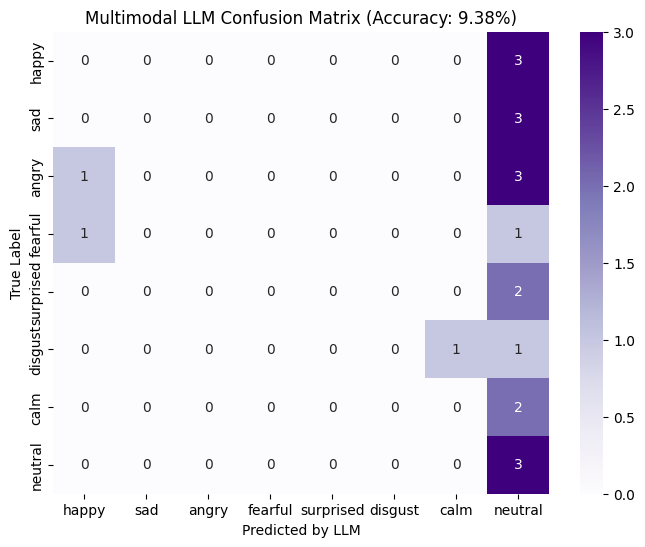

In [ ]:
llm_accuracy = accuracy_score(y_true, y_pred_llm)
print(f"\n--- LLM Evaluation Complete ---")
print(f"Overall LLM Accuracy: {llm_accuracy * 100:.2f}%")

labels_names = ["happy", "sad", "angry", "fearful", "surprised", "disgust", "calm", "neutral"]
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred_llm, target_names=labels_names, labels=labels_names, zero_division=0))

cm = confusion_matrix(y_true, y_pred_llm, labels=labels_names)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", xticklabels=labels_names, yticklabels=labels_names)
plt.xlabel("Predicted by LLM")
plt.ylabel("True Label")
plt.title(f"Multimodal LLM Confusion Matrix (Accuracy: {llm_accuracy*100:.2f}%)")
plt.show()

In [ ]:
import json
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

llm_results = {
    "model_name": "Multimodal LLM (Gemini)",
    "accuracy": accuracy_score(y_true, y_pred_llm),
    "classification_report": classification_report(y_true, y_pred_llm, output_dict=True, zero_division=0),
    "confusion_matrix": confusion_matrix(y_true, y_pred_llm, labels=labels_names).tolist()
}

with open("metrics_llm.json", 'w', encoding='utf-8') as f:
    json.dump(llm_results, f, indent=4)

##### LLMs evaluation 2.0:

In [ ]:
import os
import time
import pandas as pd
import google.generativeai as genai
from tqdm.auto import tqdm
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import userdata

GOOGLE_API_KEY = userdata.get('GOOGLE_API_KEY')
genai.configure(api_key=GOOGLE_API_KEY)
model = genai.GenerativeModel('gemini-2.5-flash')
print("API configured successfully!")

system_prompt = """
You are an expert in Speech Emotion Recognition and Acoustic Analysis.
Listen to the provided Ukrainian audio file.

CRITICAL INSTRUCTION: Completely IGNORE the meaning of the spoken words. The sentences are intentionally mundane.
You MUST analyze ONLY the acoustic features of the voice: pitch, volume, speaking rate, breathiness, and vocal tension.

Based strictly on the acoustic tone of the speaker's voice, classify the emotion.
You MUST choose exactly ONE label from the following list:
happy, sad, angry, fearful, surprised, disgust, calm, neutral.

Output ONLY the label word in English. Do not provide any punctuation or explanations.
"""

def evaluate_llm(test_df):
    predicted_labels = []
    actual_labels = test_df['emotion'].tolist()
    valid_emotions = ["happy", "sad", "angry", "fearful", "surprised", "disgust", "calm", "neutral"]
    print("Starting LLM Evaluation (with Rate Limit Handling)...")

    for index, row in tqdm(test_df.iterrows(), total=len(test_df)):
        audio_path = row['file_path']
        prediction = "error"

        max_retries = 5
        for attempt in range(max_retries):
            try:
                uploaded_audio = genai.upload_file(path=audio_path)
                response = model.generate_content([system_prompt, uploaded_audio])
                prediction = response.text.strip().lower()

                if prediction not in valid_emotions:
                    matched = False
                    for valid_emotion in valid_emotions:
                        if valid_emotion in prediction:
                            prediction = valid_emotion
                            matched = True
                            break
                    if not matched:
                        prediction = "unknown"

                genai.delete_file(uploaded_audio.name)
                print(f"Success: {audio_path} -> {prediction}")
                time.sleep(4)
                break

            except Exception as e:
                error_msg = str(e)
                if "429" in error_msg or "Quota" in error_msg:
                    wait_time = 60 + 30 * (attempt + 1)
                    print(f"Rate limit hit. Waiting {wait_time} seconds before retry {attempt + 1}/{max_retries}...")
                    time.sleep(wait_time)
                else:
                    print(f"Non-API Error processing {audio_path}: {e}")
                    break

        predicted_labels.append(prediction)

    return actual_labels, predicted_labels

y_true, y_pred_llm = evaluate_llm(ukr_test_df)

API configured successfully!
Starting LLM Evaluation (with Rate Limit Handling)...


  0%|          | 0/32 [00:00<?, ?it/s]

Success: ./ukr_test_dataset/actor 11/07-02-11.ogg -> neutral
Success: ./ukr_test_dataset/actor 11/07-01-11.ogg -> neutral
Success: ./ukr_test_dataset/actor 11/02-02-11.ogg -> neutral
Success: ./ukr_test_dataset/actor 11/05-01-11.ogg -> neutral
Success: ./ukr_test_dataset/actor 11/04-02-11.ogg -> neutral
Success: ./ukr_test_dataset/actor 11/04-01-11.ogg -> neutral
Success: ./ukr_test_dataset/actor 11/06-01-11.ogg -> calm
Success: ./ukr_test_dataset/actor 11/01-01-11.ogg -> neutral
Success: ./ukr_test_dataset/actor 11/08-01-11.ogg -> neutral
Success: ./ukr_test_dataset/actor 11/03-01-11.ogg -> neutral
Success: ./ukr_test_dataset/actor 11/05-02-11.ogg -> neutral
Success: ./ukr_test_dataset/actor 11/03-02-11.ogg -> neutral
Success: ./ukr_test_dataset/actor 11/06-02-11.ogg -> neutral
Success: ./ukr_test_dataset/actor 11/01-02-11.ogg -> calm
Success: ./ukr_test_dataset/actor 11/08-02-11.ogg -> neutral
Success: ./ukr_test_dataset/actor 11/02-01-11.ogg -> neutral
Success: ./ukr_test_dataset/ac

In [ ]:
print(y_pred_llm)

['neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'calm', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'calm', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral']



--- LLM Evaluation Complete ---
Overall LLM Accuracy: 12.50%

Classification Report:

              precision    recall  f1-score   support

       happy       0.00      0.00      0.00         4
         sad       0.00      0.00      0.00         4
       angry       0.00      0.00      0.00         4
     fearful       0.00      0.00      0.00         4
   surprised       0.00      0.00      0.00         4
     disgust       0.00      0.00      0.00         4
        calm       0.00      0.00      0.00         4
     neutral       0.13      1.00      0.24         4

    accuracy                           0.12        32
   macro avg       0.02      0.12      0.03        32
weighted avg       0.02      0.12      0.03        32



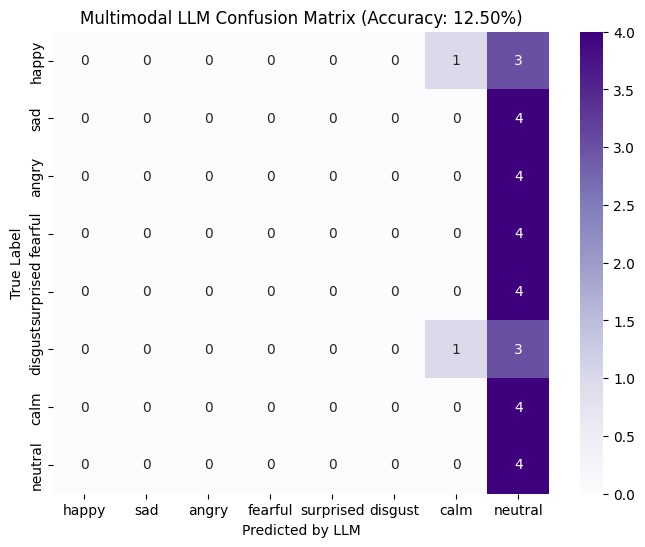

In [ ]:
llm_accuracy = accuracy_score(y_true, y_pred_llm)
print(f"\n--- LLM Evaluation Complete ---")
print(f"Overall LLM Accuracy: {llm_accuracy * 100:.2f}%")

labels_names = ["happy", "sad", "angry", "fearful", "surprised", "disgust", "calm", "neutral"]
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred_llm, target_names=labels_names, labels=labels_names, zero_division=0))

cm = confusion_matrix(y_true, y_pred_llm, labels=labels_names)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", xticklabels=labels_names, yticklabels=labels_names)
plt.xlabel("Predicted by LLM")
plt.ylabel("True Label")
plt.title(f"Multimodal LLM Confusion Matrix (Accuracy: {llm_accuracy*100:.2f}%)")
plt.show()

In [ ]:
import json
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

llm_results = {
    "model_name": "Multimodal LLM (Gemini)",
    "accuracy": accuracy_score(y_true, y_pred_llm),
    "classification_report": classification_report(y_true, y_pred_llm, output_dict=True, zero_division=0),
    "confusion_matrix": confusion_matrix(y_true, y_pred_llm, labels=labels_names).tolist()
}

with open("metrics_llm.json", 'w', encoding='utf-8') as f:
    json.dump(llm_results, f, indent=4)

##### Results analysis:

--- Overall Model Comparison ---


,Model,Accuracy (%),Macro Precision,Macro Recall,Macro F1-Score
0,Zero-Shot,12.50,5.51,12.50,5.92
1,Base HuBERT,37.50,54.58,37.50,34.42
2,Finetuned Bachelor,28.12,24.16,28.12,20.69
3,Multimodal LLM,12.50,1.67,12.50,2.94


<Figure size 1400x700 with 0 Axes>

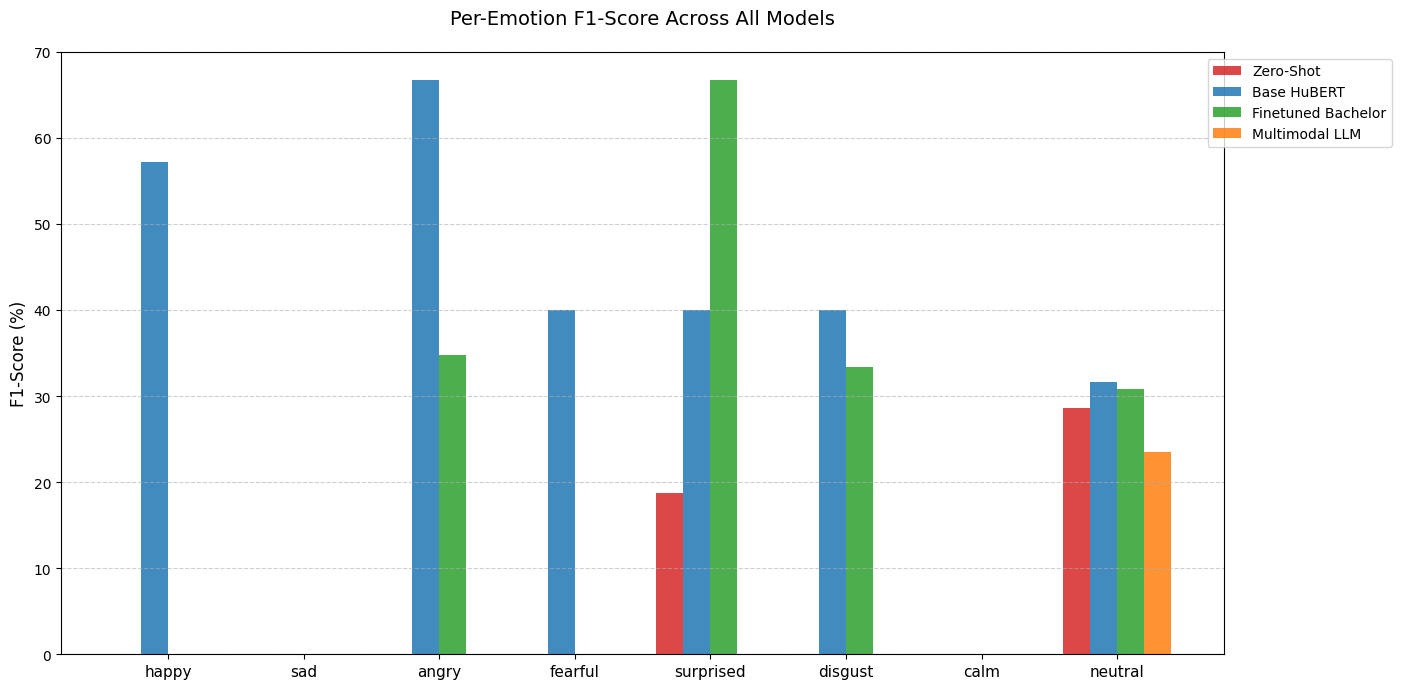

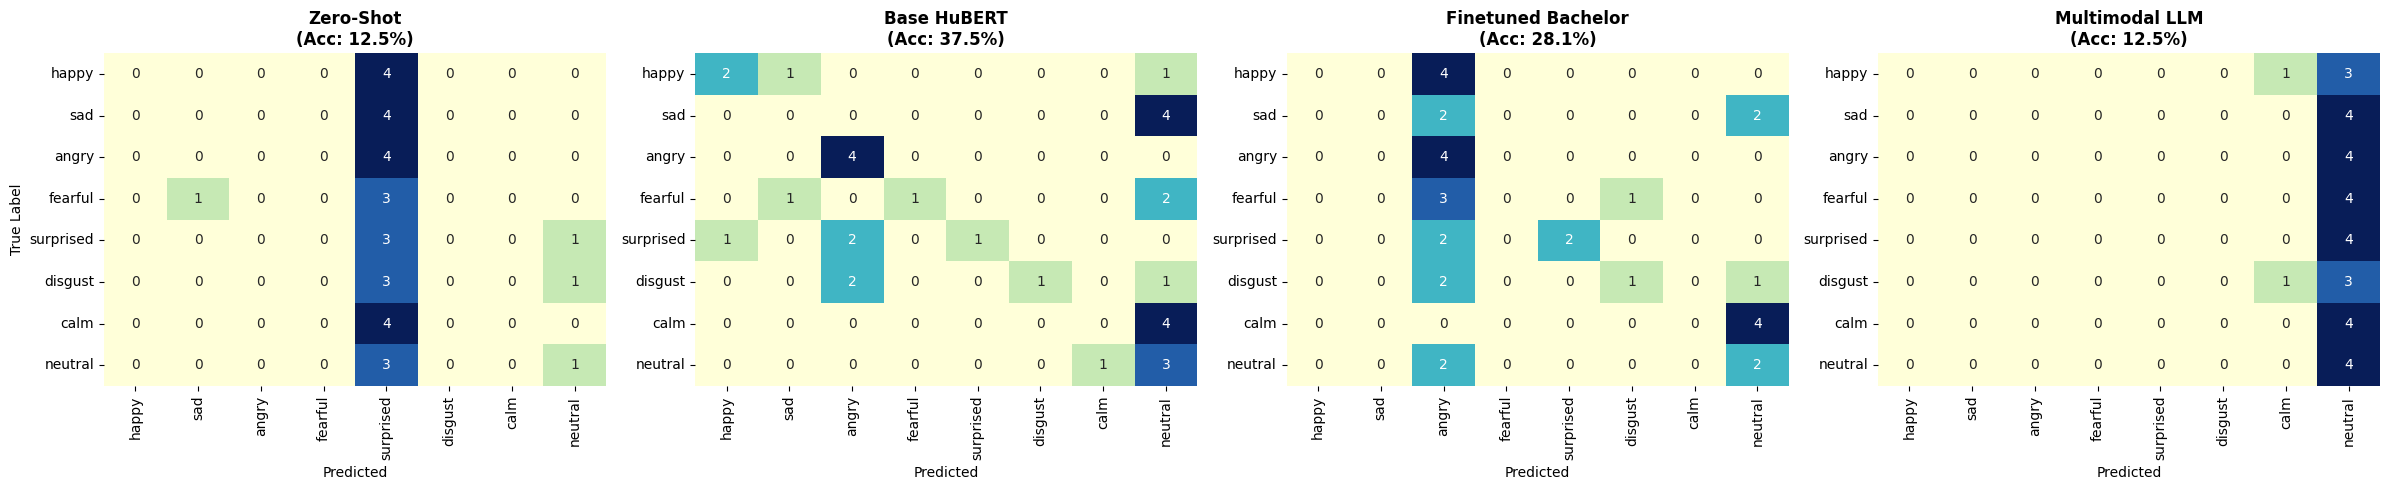

In [14]:
import json
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

labels_names = ["happy", "sad", "angry", "fearful", "surprised", "disgust", "calm", "neutral"]
json_files = {
    "Zero-Shot": "metrics_zero_shot.json",
    "Base HuBERT": "metrics_base.json",
    "Finetuned Bachelor": "metrics_bachelor.json",
    "Multimodal LLM": "metrics_llm.json"
}
loaded_data = {}

for name, filepath in json_files.items():
    if os.path.exists(filepath):
        with open(filepath, "r", encoding="utf-8") as f:
            loaded_data[name] = json.load(f)
    else:
        print(f"Warning: {filepath} not found. Skipping {name}.")

table_rows = []
for name, data in loaded_data.items():
    report = data["classification_report"]
    table_rows.append({
        "Model": name,
        "Accuracy (%)": data["accuracy"] * 100,
        "Macro Precision": report["macro avg"]["precision"] * 100,
        "Macro Recall": report["macro avg"]["recall"] * 100,
        "Macro F1-Score": report["macro avg"]["f1-score"] * 100
    })

df_metrics = pd.DataFrame(table_rows).round(2)
print("--- Overall Model Comparison ---")
display(df_metrics)
plt.figure(figsize=(14, 7))

x = np.arange(len(labels_names))
num_models = len(loaded_data)
width = 0.8 / num_models
multiplier = 0

colors = ['#d62728', '#1f77b4', '#2ca02c', '#ff7f0e']

fig, ax = plt.subplots(figsize=(14, 7))

for (name, data), color in zip(loaded_data.items(), colors):
    report = data["classification_report"]
    f1_scores = []
    for i, label in enumerate(labels_names):
        if str(i) in report:
            f1_scores.append(report[str(i)]["f1-score"])
        elif label in report:
            f1_scores.append(report[label]["f1-score"])
        else:
            f1_scores.append(0)

    offset = width * multiplier
    rects = ax.bar(x + offset, np.array(f1_scores) * 100, width, label=name, color=color, alpha=0.85)
    multiplier += 1

ax.set_ylabel('F1-Score (%)', fontsize=12)
ax.set_title('Per-Emotion F1-Score Across All Models', fontsize=14, pad=20)
ax.set_xticks(x + width * (num_models - 1) / 2)
ax.set_xticklabels(labels_names, fontsize=11)
ax.legend(loc='upper right', bbox_to_anchor=(1.15, 1))
ax.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, len(loaded_data), figsize=(6 * len(loaded_data), 5))

if len(loaded_data) == 1:
    axes = [axes]

for ax, (name, data) in zip(axes, loaded_data.items()):
    cm = np.array(data["confusion_matrix"])
    cm_perc = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_perc = np.nan_to_num(cm_perc) * 100
    sns.heatmap(cm_perc, annot=cm, fmt="d", cmap="YlGnBu",
                xticklabels=labels_names, yticklabels=labels_names, ax=ax, cbar=False)

    ax.set_title(f'{name}\n(Acc: {data["accuracy"]*100:.1f}%)', fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted', fontsize=10)
    if ax == axes[0]:
        ax.set_ylabel('True Label', fontsize=10)

plt.tight_layout()
plt.show()

##### Results analysis 2.0:

--- Overall Model Comparison ---


,Model,Accuracy (%),Macro Precision,Macro Recall,Macro F1-Score
0,Zero-Shot,12.50,5.51,12.50,5.92
1,Base HuBERT,37.50,54.58,37.50,34.42
2,Finetuned Bachelor,28.12,24.16,28.12,20.69
3,Multimodal LLM,12.50,1.67,12.50,2.94


<Figure size 1400x700 with 0 Axes>

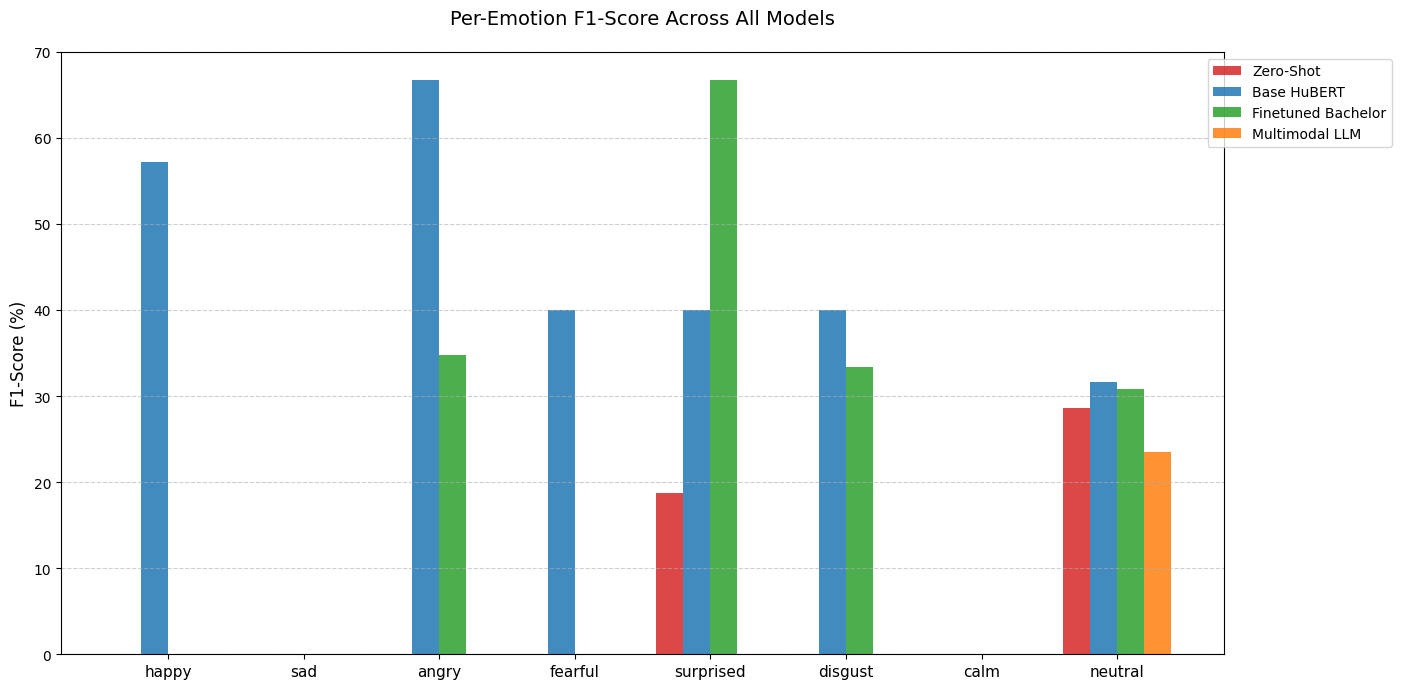

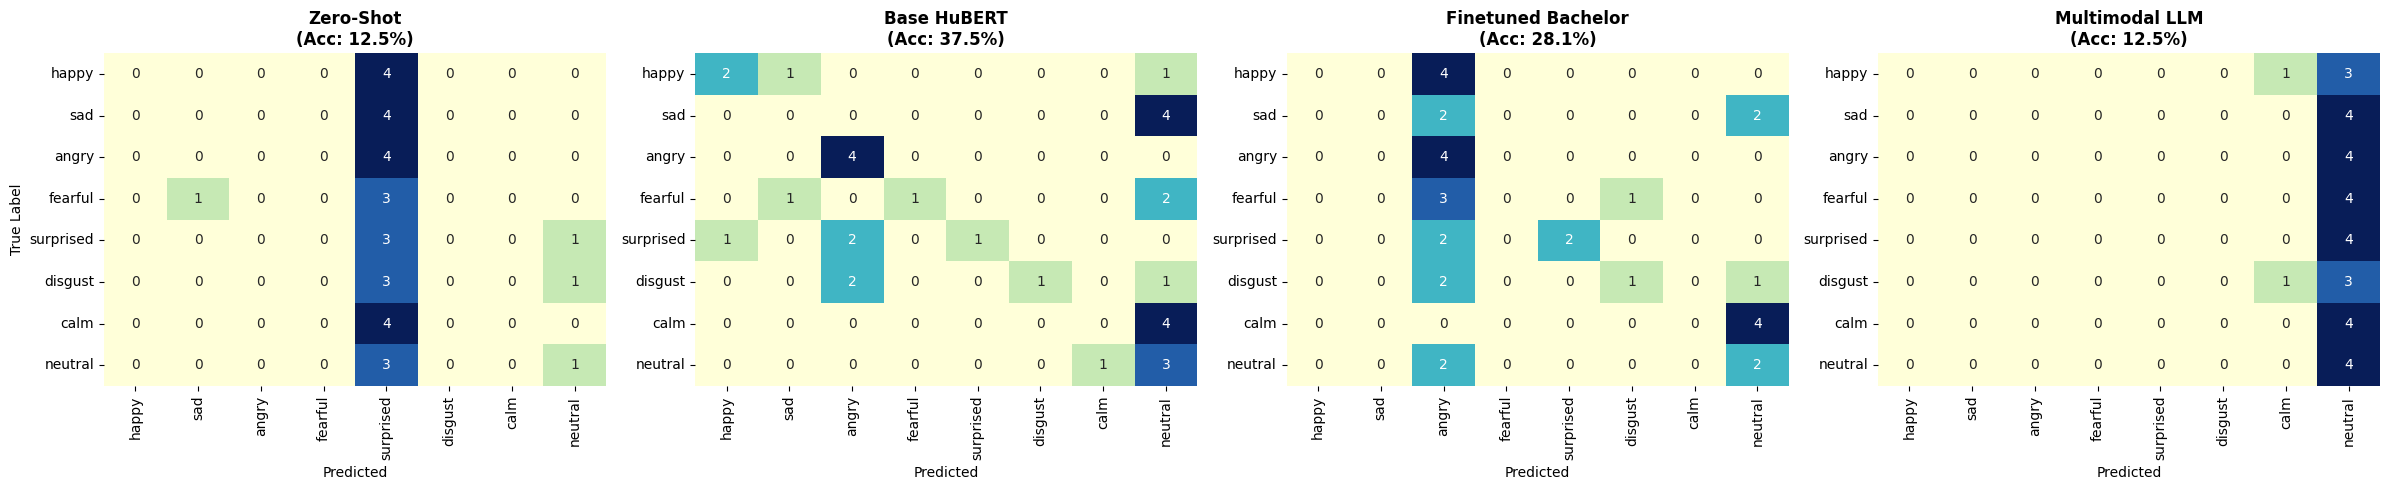

In [15]:
import json
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

labels_names = ["happy", "sad", "angry", "fearful", "surprised", "disgust", "calm", "neutral"]
json_files = {
    "Zero-Shot": "metrics_zero_shot.json",
    "Base HuBERT": "metrics_base.json",
    "Finetuned Bachelor": "metrics_bachelor.json",
    "Multimodal LLM": "metrics_llm.json"
}
loaded_data = {}

for name, filepath in json_files.items():
    if os.path.exists(filepath):
        with open(filepath, "r", encoding="utf-8") as f:
            loaded_data[name] = json.load(f)
    else:
        print(f"Warning: {filepath} not found. Skipping {name}.")

table_rows = []
for name, data in loaded_data.items():
    report = data["classification_report"]
    table_rows.append({
        "Model": name,
        "Accuracy (%)": data["accuracy"] * 100,
        "Macro Precision": report["macro avg"]["precision"] * 100,
        "Macro Recall": report["macro avg"]["recall"] * 100,
        "Macro F1-Score": report["macro avg"]["f1-score"] * 100
    })

df_metrics = pd.DataFrame(table_rows).round(2)
print("--- Overall Model Comparison ---")
display(df_metrics)
plt.figure(figsize=(14, 7))

x = np.arange(len(labels_names))
num_models = len(loaded_data)
width = 0.8 / num_models
multiplier = 0

colors = ['#d62728', '#1f77b4', '#2ca02c', '#ff7f0e']

fig, ax = plt.subplots(figsize=(14, 7))

for (name, data), color in zip(loaded_data.items(), colors):
    report = data["classification_report"]
    f1_scores = []
    for i, label in enumerate(labels_names):
        if str(i) in report:
            f1_scores.append(report[str(i)]["f1-score"])
        elif label in report:
            f1_scores.append(report[label]["f1-score"])
        else:
            f1_scores.append(0)

    offset = width * multiplier
    rects = ax.bar(x + offset, np.array(f1_scores) * 100, width, label=name, color=color, alpha=0.85)
    multiplier += 1

ax.set_ylabel('F1-Score (%)', fontsize=12)
ax.set_title('Per-Emotion F1-Score Across All Models', fontsize=14, pad=20)
ax.set_xticks(x + width * (num_models - 1) / 2)
ax.set_xticklabels(labels_names, fontsize=11)
ax.legend(loc='upper right', bbox_to_anchor=(1.15, 1))
ax.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, len(loaded_data), figsize=(6 * len(loaded_data), 5))

if len(loaded_data) == 1:
    axes = [axes]

for ax, (name, data) in zip(axes, loaded_data.items()):
    cm = np.array(data["confusion_matrix"])
    cm_perc = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_perc = np.nan_to_num(cm_perc) * 100
    sns.heatmap(cm_perc, annot=cm, fmt="d", cmap="YlGnBu",
                xticklabels=labels_names, yticklabels=labels_names, ax=ax, cbar=False)

    ax.set_title(f'{name}\n(Acc: {data["accuracy"]*100:.1f}%)', fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted', fontsize=10)
    if ax == axes[0]:
        ax.set_ylabel('True Label', fontsize=10)

plt.tight_layout()
plt.show()

#### Utils:

In [7]:
!pip install graphviz pandas

In [8]:
import pandas as pd
import graphviz

# ==========================================
# TABLE I: Summary of UA-SER Dataset Structure
# ==========================================
table_i_data = [
    {"Emotion": "Happy", "Code": 1, "Utterances": "Phrase 1 / Phrase 2", "Train Count": 200, "Val Count": 20, "Test Count": 24, "Total": 244},
    {"Emotion": "Sad", "Code": 2, "Utterances": "Phrase 1 / Phrase 2", "Train Count": 181, "Val Count": 20, "Test Count": 26, "Total": 227},
    {"Emotion": "Angry", "Code": 3, "Utterances": "Phrase 1 / Phrase 2", "Train Count": 210, "Val Count": 20, "Test Count": 29, "Total": 259},
    {"Emotion": "Fearful", "Code": 4, "Utterances": "Phrase 1 / Phrase 2", "Train Count": 150, "Val Count": 15, "Test Count": 20, "Total": 185},
    {"Emotion": "Surprised", "Code": 5, "Utterances": "Phrase 1 / Phrase 2", "Train Count": 140, "Val Count": 15, "Test Count": 18, "Total": 173},
    {"Emotion": "Disgust", "Code": 6, "Utterances": "Phrase 1 / Phrase 2", "Train Count": 130, "Val Count": 15, "Test Count": 15, "Total": 160},
    {"Emotion": "Calm", "Code": 7, "Utterances": "Phrase 1 / Phrase 2", "Train Count": 160, "Val Count": 15, "Test Count": 20, "Total": 195},
    {"Emotion": "Neutral", "Code": 8, "Utterances": "Phrase 1 / Phrase 2", "Train Count": 180, "Val Count": 20, "Test Count": 22, "Total": 222},
]

df_table_i = pd.DataFrame(table_i_data)
print("--- Table I: Summary of the UA-SER Dataset Structure ---")
display(df_table_i)
print("\n" + "="*50 + "\n")


# ==========================================
# TABLE II: Hyperparameter Configuration
# ==========================================
table_ii_data = [
    {"Parameter": "Architecture", "Value": "HuBERT-Large"},
    {"Parameter": "Learning Rate", "Value": "3e-5"},
    {"Parameter": "Optimizer", "Value": "AdamW"},
    {"Parameter": "Weight Decay", "Value": "0.01"},
    {"Parameter": "Batch Size", "Value": "8"},
    {"Parameter": "Gradient Accumulation", "Value": "2"},
    {"Parameter": "Epochs", "Value": "10"},
    {"Parameter": "Warmup Steps", "Value": "20"},
]

df_table_ii = pd.DataFrame(table_ii_data)
print("--- Table II: Hyperparameter Configuration ---")
display(df_table_ii)
print("\n" + "="*50 + "\n")


# ==========================================
# FIGURE 1: End-to-End System Pipeline (B&W)
# ==========================================
# Creates a minimal, publication-ready black & white flowchart block diagram
pipeline = graphviz.Digraph('End_to_End_Pipeline', comment='System Pipeline')
pipeline.attr(rankdir='LR', fontname='Helvetica', fontsize='11')

# Strict black and white academic styling
pipeline.attr('node', shape='box', style='rounded,filled', fillcolor='white', color='black', fontname='Helvetica', fontsize='10', margin='0.15')
pipeline.attr('edge', color='black', arrowhead='vee', arrowsize='0.7')

# Add nodes
pipeline.node('Input', 'Raw Audio\n(48 kHz .ogg / .m4a)')
pipeline.node('Resample', 'Resampling\n(16 kHz Mono)')
pipeline.node('Backbone', 'HuBERT Backbone\n(CNN Encoder + Transformer)')
pipeline.node('Pooling', 'Mean Pooling')
pipeline.node('Head', 'Linear Classification Head')
pipeline.node('Output', '8 Emotion Logits')

# Define edges
pipeline.edge('Input', 'Resample')
pipeline.edge('Resample', 'Backbone')
pipeline.edge('Backbone', 'Pooling')
pipeline.edge('Pooling', 'Head')
pipeline.edge('Head', 'Output')

# Render pipeline graphic to file (outputs 'pipeline_figure.png')
pipeline.render('pipeline_figure', format='png', cleanup=True)
print("Figure 1 saved successfully as 'pipeline_figure.png'.")

--- Table I: Summary of the UA-SER Dataset Structure ---


,Emotion,Code,Utterances,Train Count,Val Count,Test Count,Total
0,Happy,1,Phrase 1 / Phrase 2,200,20,24,244
1,Sad,2,Phrase 1 / Phrase 2,181,20,26,227
2,Angry,3,Phrase 1 / Phrase 2,210,20,29,259
3,Fearful,4,Phrase 1 / Phrase 2,150,15,20,185
4,Surprised,5,Phrase 1 / Phrase 2,140,15,18,173
5,Disgust,6,Phrase 1 / Phrase 2,130,15,15,160
6,Calm,7,Phrase 1 / Phrase 2,160,15,20,195
7,Neutral,8,Phrase 1 / Phrase 2,180,20,22,222




--- Table II: Hyperparameter Configuration ---


,Parameter,Value
0,Architecture,HuBERT-Large
1,Learning Rate,3e-5
2,Optimizer,AdamW
3,Weight Decay,0.01
4,Batch Size,8
5,Gradient Accumulation,2
6,Epochs,10
7,Warmup Steps,20




Figure 1 saved successfully as 'pipeline_figure.png'.


In [ ]:
import shutil
import os

folder_path = "/content/ukr_dataset"
# folder_path = "/content/ukr_train_dataset"
# folder_path = "/content/ukr_test_dataset"
# folder_path = "/content/ukr_val_dataset"
# folder_path = "/content/hubert_base_ukr_finetuned"
# folder_path = "/content/hubert_bachelor_ukr_finetuned"

if os.path.exists(folder_path):
    shutil.rmtree(folder_path)
    print("Folder deleted")
else:
    print("Folder does not exist")

Folder deleted


In [ ]:
import google.generativeai as genai

print("Available models:")
for m in genai.list_models():
    if 'generateContent' in m.supported_generation_methods:
        print(m.name)

Available models:
models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.0-flash
models/gemini-2.0-flash-001
models/gemini-2.0-flash-lite-001
models/gemini-2.0-flash-lite
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-pro-preview
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.5-flash
models/lyria-3-clip-preview
models/lyria-3-pro-preview
models/gemini-3.1-flash-tts-preview
models/gemini-robotics-er-1.5-preview
models/gemini-robotics-er-1.6-preview
models/gemini-2.5-computer-use-preview-10-2025
models/antigravity-previ

In [ ]:
from google.colab import files

# files.download('/content/metrics_llm.json')
files.download('/content/hubert_bachelor_ukr_finetuned')
files.download('/content/hubert_base_ukr_finetuned')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>